# Difference-in-Differences — Medicaid Expansion and the Uninsured Rate

**Artifact class:** `causal_analysis`  ·  **Data mode:** `empirical`  ·  **Vintage:** ACS 1-year, 2010–2019 and 2021–2023 (each year pinned)

This notebook uses **real data only**. There is no synthetic generator and no fallback. If a
retrieval fails, a key is absent or a value leaves its stated range, the notebook stops.

The analysis was fixed in a **pre-analysis plan** (`pap/C01_pap.md`) that was committed before any
table below was retrieved. The notebook is bound to that file by its SHA-256, and says where it
departs from it.

*Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

By the end of this notebook you will be able to:

1. **State** a difference-in-differences estimand, and say which assumption stands between the
   estimate and a causal reading of it.
2. **Compute** a two-by-two difference-in-differences by hand from four group means, and show that
   a two-way fixed-effects regression returns the same number.
3. **Read** an event-study plot, and explain why the leads — not the lags — are the argument.
4. **Run** two falsification tests (a joint test of pre-period coefficients and a placebo outcome),
   and apply a decision rule that was written down before the data were seen.
5. **Report** inference honestly when there are few clusters, using a wild-cluster bootstrap.

## Prerequisites

**Knowledge.** Linear regression with fixed effects; the idea of a counterfactual; what a
cluster-robust standard error is for.

**Setup.** A free Census API key from <https://api.census.gov/data/key_signup.html>, supplied by
you as the environment variable `CENSUS_API_KEY`, or as a line `CENSUS_API_KEY=...` in a file whose
path you set in `KRL_SECRETS_PATH`. The key is read at runtime and is never printed or written
into this notebook's output.

**Packages.** `pandas`, `numpy`, `scipy`, `matplotlib`, `requests`, and the local
`krl_tutorials_data` package (its `methods.did` module holds the estimators).

**Prior notebooks.** None are required. D01 explains the Census API client used here.

## Data Provenance

| Item | Source | Role |
|---|---|---|
| `B27010_034E`, `B27010_050E` | ACS 1-year detail table B27010, state × year | uninsured rate, ages 35–64 (outcome) |
| `B27010_051E`, `B27010_066E` | the same table | uninsured rate, ages 65 and over (placebo outcome) |
| `data/policy/medicaid/expansion_dates.csv` | KFF, *Status of State Action on the Medicaid Expansion Decision* | treatment timing |

The Census Bureau publishes no standard 2020 ACS 1-year release, so 2020 is absent. Every variable's
published label for each year is retrieved from the Census variables endpoint and recorded in that
year's provenance file. Each record also carries the SHA-256 of the pre-analysis plan.

> **Why ages 35–64 and not 19–64.** The ACS changed its age bands in 2017 (B27010 reads "18 to 34"
> through 2016 and "19 to 34" after), so no consistent 19–64 series exists for 2010–2023. The 35–64
> band is the one adult band whose definition does not change. The plan records this choice before the data were
> retrieved.

## Design and identification

**Estimand.** The average effect of Medicaid expansion on the uninsured rate of adults aged 35–64,
for the states that expanded on 1 January 2014, averaged over 2014–2019, in percentage points.

**Assumption.** Parallel trends: absent expansion, the uninsured rate in expansion states would
have moved as it did in the states that never expanded. It cannot be tested for the post-period.
What can be tested is its pre-period shadow — whether the two groups were moving together before 2014.

**Decision rule, fixed in the plan.** The effect counts as null if the 95% wild-bootstrap interval
contains zero. It counts as credibly identified only if the joint pre-trend test does not reject at
the 10% level **and** the placebo effect on ages 65 and over has an interval containing zero.

In [1]:
"""Configuration. Every analytic choice is named here, not inferred."""
from __future__ import annotations

import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels.api as sm
from scipy import stats

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src"))
        REPO_ROOT = _cand
        break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.methods import did
from krl_tutorials_data.sources import DataAccessError, fetch_acs

NB_DIR = REPO_ROOT / "projects" / "09-causal-identification" / "C01_medicaid_expansion_did"
PAP = NB_DIR / "pap" / "C01_pap.md"
PAP_SHA256 = hashlib.sha256(PAP.read_bytes()).hexdigest()

YEARS = [y for y in range(2010, 2024) if y != 2020]          # no standard 2020 ACS 1-year
PRIMARY = [y for y in YEARS if y <= 2019]
FIRST_TREATED_YEAR = 2014
N_BOOT, SEED = 9999, 20261022
ADDED = "not pre-specified (added after review, 2026-10-23)"
POST_LABEL = f"{FIRST_TREATED_YEAR}-{PRIMARY[-1]}"

print(f"pre-analysis plan : {PAP.relative_to(REPO_ROOT)}")
print(f"plan SHA-256      : {PAP_SHA256}")
print(f"years retrieved   : {YEARS[0]}-{YEARS[-1]} without 2020 ({len(YEARS)} vintages)")

pre-analysis plan : projects/09-causal-identification/C01_medicaid_expansion_did/pap/C01_pap.md
plan SHA-256      : 06eae187e52ae408bf7857808caf42525360e68594802aefc5ad550fd14e494c
years retrieved   : 2010-2023 without 2020 (13 vintages)


### Retrieving the data

One request per year, each to the ACS 1-year endpoint for that year, so every vintage is addressed
separately. Values outside a stated plausible range stop the notebook rather than flow into an
estimate. An earlier version of this check set the lower bound for the count of uninsured people aged 65 and over too high, and a real survey value stopped the run (it is printed below). That value is not malformed - Medicare covers almost everyone in this group - so the bound was a wrong expectation, not a data error; it is now zero. Puerto Rico is returned by the API and dropped later: the policy table covers the 50 states
and the District of Columbia.

In [2]:
CODES = {
    "B27010_034E": "ages 35-64, total",
    "B27010_050E": "ages 35-64, no health insurance coverage",
    "B27010_051E": "ages 65 and over, total",
    "B27010_066E": "ages 65 and over, no health insurance coverage",
}
PLAUSIBLE = {
    "B27010_034E": (100_000, 20_000_000),
    "B27010_050E": (1_000, 5_000_000),
    "B27010_051E": (30_000, 10_000_000),
    "B27010_066E": (0, 500_000),   # near zero by design: Medicare covers almost everyone 65+
}


def published_labels(year: int) -> dict[str, str]:
    """The label the Census Bureau publishes for each variable in this vintage."""
    url = f"https://api.census.gov/data/{year}/acs/acs1/variables.json"
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    variables = response.json()["variables"]
    return {code: variables[code]["label"] for code in CODES}


frames, records = [], {}
try:
    for year in YEARS:
        frame, prov = fetch_acs(
            year=year, variables=published_labels(year), dataset="acs/acs1",
            geography="state:*", plausible=PLAUSIBLE,
        )
        frame["year"] = year
        frames.append(frame)
        records[year] = prov.with_pap(PAP)
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    raise

raw = pd.concat(frames, ignore_index=True)
out_dir = NB_DIR / "provenance"
for year, record in records.items():
    record.write(out_dir / f"c01_acs1_b27010_{year}.json")

print(f"rows retrieved    : {len(raw):,} ({raw['year'].nunique()} years x {raw['NAME'].nunique()} geographies)")
print(f"records written   : {len(records)}, each bound to the plan digest {PAP_SHA256[:12]}...")
print(records[2014].render())

low = raw.loc[raw["B27010_066E"].idxmin()]
print(f"smallest count of uninsured people aged 65 and over in any state-year: {int(low['B27010_066E'])} of {int(low['B27010_051E']):,} ({low['NAME']}, {int(low['year'])})")

rows retrieved    : 676 (13 years x 52 geographies)
records written   : 13, each bound to the plan digest 06eae187e52a...
Source      : U.S. Census Bureau - American Community Survey (acs/acs1)
Vintage     : 2014  (pinned)
Endpoint    : https://api.census.gov/data/2014/acs/acs1
Retrieved   : 2026-10-23T19:59:38+00:00
Shape       : 52 rows x 6 cols
Payload hash: 6d02457b7f02f193...  (canonical-rows)
Data mode   : EMPIRICAL
Plan digest : 06eae187e52ae408...  (pre-analysis plan)
Variables   :
              B27010_034E      Estimate!!Total!!35 to 64 years
              B27010_050E      Estimate!!Total!!35 to 64 years!!No health insurance coverage
              B27010_051E      Estimate!!Total!!65 years and over
              B27010_066E      Estimate!!Total!!65 years and over!!No health insurance coverage
Limitations :
              - ACS estimates are survey-based and carry margins of error that are not retrieved here; differences between geographies may not be statistically distinguishab

In [3]:
"""Join the treatment table and apply the plan's sample rule."""
policy = pd.read_csv(REPO_ROOT / "data" / "policy" / "medicaid" / "expansion_dates.csv")


def assign_group(row: pd.Series) -> str:
    if row["expansion_effective"] == "2014-01-01":
        return "treated"
    if row["status"] == "Not Adopted":
        return "control"
    if str(row["expansion_effective"]).startswith("2014"):
        return "excluded: partial first year"
    return "excluded: later adopter"


policy["group"] = policy.apply(assign_group, axis=1)
counts = policy["group"].value_counts()
print(counts.to_string())

EXPECTED = {"treated": 25, "control": 10, "excluded: partial first year": 2, "excluded: later adopter": 14}
if {k: int(counts.get(k, 0)) for k in EXPECTED} != EXPECTED:
    raise SystemExit("The sample does not match the pre-analysis plan; stop and explain why.")
print()
print("Sample matches the plan: 25 treated, 10 control, 16 excluded.")

panel = raw.rename(columns={"state": "fips"}).merge(policy[["state", "group"]], left_on="NAME", right_on="state", how="inner")
panel = panel[panel["group"].isin(["treated", "control"])].copy()
panel["treated"] = (panel["group"] == "treated").astype(int)
panel["unins_35_64"] = 100.0 * panel["B27010_050E"] / panel["B27010_034E"]
panel["unins_65p"] = 100.0 * panel["B27010_066E"] / panel["B27010_051E"]
panel["post"] = (panel["year"] >= FIRST_TREATED_YEAR).astype(int)
panel["D"] = panel["treated"] * panel["post"]
print(f"analysis panel: {panel['state'].nunique()} states x {panel['year'].nunique()} years = {len(panel)} rows")

group
treated                         25
excluded: later adopter         14
control                         10
excluded: partial first year     2

Sample matches the plan: 25 treated, 10 control, 16 excluded.
analysis panel: 35 states x 13 years = 455 rows


group  control  treated
year                   
2010     18.71    14.13
2011     19.22    14.28
2012     18.98    14.21
2013     18.89    14.40
2014     16.17    10.29
2015     13.95     7.95
2016     13.31     7.34
2017     13.91     7.64
2018     14.13     7.72
2019     14.51     8.15
2021     13.90     7.88
2022     12.89     7.32
2023     12.31     7.29


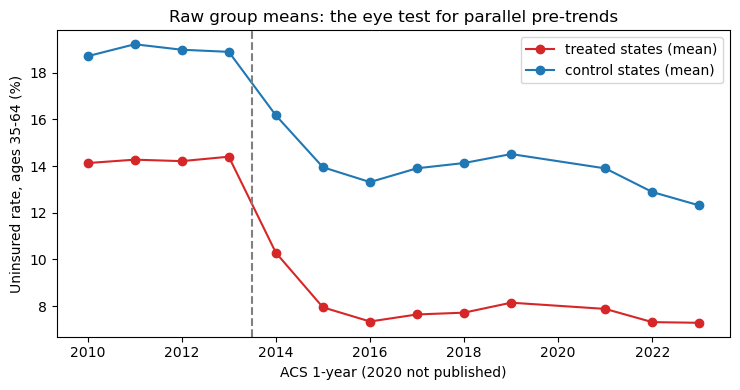

Treated minus control, 2010-2013 (pp): -4.58, -4.94, -4.77, -4.49


In [4]:
"""What the two groups looked like before the model."""
trend = panel.groupby(["year", "group"])["unins_35_64"].mean().unstack("group")
print(trend.round(2).to_string())

fig, ax = plt.subplots(figsize=(7.5, 4))
for name, colour in (("treated", "tab:red"), ("control", "tab:blue")):
    ax.plot(trend.index, trend[name], marker="o", color=colour, label=f"{name} states (mean)")
ax.axvline(2013.5, color="grey", linestyle="--")
ax.set_ylabel("Uninsured rate, ages 35-64 (%)")
ax.set_xlabel("ACS 1-year (2020 not published)")
ax.set_title("Raw group means: the eye test for parallel pre-trends")
ax.legend()
plt.tight_layout()
plt.show()

pre_gap = (trend.loc[2010:2013, "treated"] - trend.loc[2010:2013, "control"])
print(f"Treated minus control, 2010-2013 (pp): {', '.join(f'{v:.2f}' for v in pre_gap)}")

### The two-by-two, by hand

Strip the design to four numbers. Average each state's rate over the pre-period (2010–2013) and the
post-period (2014–2019); average those state means within each group; then take the difference of the
two changes. Nothing else is happening in the estimate.

In [5]:
"""The clean 2x2, computed from group means and checked against the library."""
state_means = (
    panel[panel["year"].isin(PRIMARY)]
    .assign(period=lambda d: np.where(d["post"] == 1, "post", "pre"))
    .groupby(["state", "group", "period"])["unins_35_64"].mean()
    .unstack("period")
    .reset_index()
)
cell = state_means.groupby("group")[["pre", "post"]].mean()
print(cell.round(3).to_string())

by_hand = (cell.loc["treated", "post"] - cell.loc["treated", "pre"]) - (
    cell.loc["control", "post"] - cell.loc["control", "pre"]
)
t_rows, c_rows = state_means[state_means["group"] == "treated"], state_means[state_means["group"] == "control"]
from_library = did.did_two_by_two(t_rows["pre"], t_rows["post"], c_rows["pre"], c_rows["post"])
print()
print(f"change in treated states : {cell.loc['treated', 'post'] - cell.loc['treated', 'pre']:+.3f} pp")
print(f"change in control states : {cell.loc['control', 'post'] - cell.loc['control', 'pre']:+.3f} pp")
print(f"2x2 by hand              : {by_hand:+.4f} pp")
print(f"2x2 from the library     : {from_library:+.4f} pp")
assert abs(by_hand - from_library) < 1e-9

period      pre    post
group                  
control  18.951  14.331
treated  14.254   8.182

change in treated states : -6.072 pp
change in control states : -4.619 pp
2x2 by hand              : -1.4530 pp
2x2 from the library     : -1.4530 pp


In [6]:
"""Two-way fixed effects: the same number, now with standard errors."""
design = panel[panel["year"].isin(PRIMARY)].sort_values(["state", "year"]).reset_index(drop=True)
y = design["unins_35_64"].to_numpy()
x = design[["D"]].to_numpy(dtype=float)
unit, time = design["state"].to_numpy(), design["year"].to_numpy()

fit = did.twfe(y, x, unit, time, cluster=unit)
att, se = float(fit.coef[0]), float(fit.se[0])
boot = did.wild_cluster_bootstrap(
    y, x, unit, time, test_column=0, n_boot=N_BOOT, seed=SEED, cluster=unit
)
crit = float(np.quantile(np.abs(boot.t_boot), 0.95))
ci_boot = (att - crit * se, att + crit * se)
t_crit = float(stats.t.ppf(0.975, fit.n_clusters - 1))
ci_cluster = (att - t_crit * se, att + t_crit * se)

print(f"states / years / rows : {fit.n_units} / {fit.n_periods} / {fit.n_obs}")
print(f"ATT (TWFE)            : {att:+.4f} pp   (2x2: {by_hand:+.4f})")
print(f"cluster-robust SE     : {se:.4f}   95% CI [{ci_cluster[0]:+.3f}, {ci_cluster[1]:+.3f}]  ({fit.n_clusters} clusters)")
print(f"wild-bootstrap p      : {boot.p_value:.4f}   95% CI [{ci_boot[0]:+.3f}, {ci_boot[1]:+.3f}]  ({N_BOOT:,} draws, seed {SEED})")
assert abs(att - by_hand) < 1e-8, "balanced single-timing panel: TWFE must equal the 2x2"

# the small-sample convention, stated: the library counts every absorbed effect in K
k_full = 1 + fit.n_units + fit.n_periods - 1
k_regs = 1 + fit.n_periods - 1                      # state effects nested in the cluster not counted
se_alt = se * float(np.sqrt((fit.n_obs - k_full) / (fit.n_obs - k_regs)))
print(f"small-sample convention: K counts all {k_full} parameters (regressor plus {fit.n_units} state and {fit.n_periods} year effects, less one); "
      f"counting only the regressor and year effects (K = {k_regs}, the usual convention for state effects nested in the cluster) gives SE {se_alt:.4f} and a 95% interval of about "
      f"[{att - crit * se_alt:+.3f}, {att + crit * se_alt:+.3f}] with the same bootstrap critical value")

states / years / rows : 35 / 10 / 350
ATT (TWFE)            : -1.4530 pp   (2x2: -1.4530)
cluster-robust SE     : 0.7278   95% CI [-2.932, +0.026]  (35 clusters)
wild-bootstrap p      : 0.0514   95% CI [-2.912, +0.006]  (9,999 draws, seed 20261022)
small-sample convention: K counts all 45 parameters (regressor plus 35 state and 10 year effects, less one); counting only the regressor and year effects (K = 10, the usual convention for state effects nested in the cluster) gives SE 0.6893 and a 95% interval of about [-2.835, -0.071] with the same bootstrap critical value


### The event study

Replace the single treatment dummy with one dummy per year relative to 2014, leaving 2013 as the
reference. The **leads** (2010–2012) are the pre-period: if the groups were moving together, they
should be near zero. The **lags** (2014–2019) trace the effect.

                               coef     se     lo     hi
event time (years from 2014)                            
-4                           -0.087  0.213 -0.520  0.345
-3                           -0.452  0.297 -1.055  0.151
-2                           -0.281  0.255 -0.800  0.237
 0                           -1.393  0.516 -2.443 -0.344
 1                           -1.509  0.798 -3.132  0.113
 2                           -1.481  0.855 -3.219  0.257
 3                           -1.771  0.846 -3.491 -0.051
 4                           -1.919  0.822 -3.589 -0.248
 5                           -1.875  0.807 -3.516 -0.234


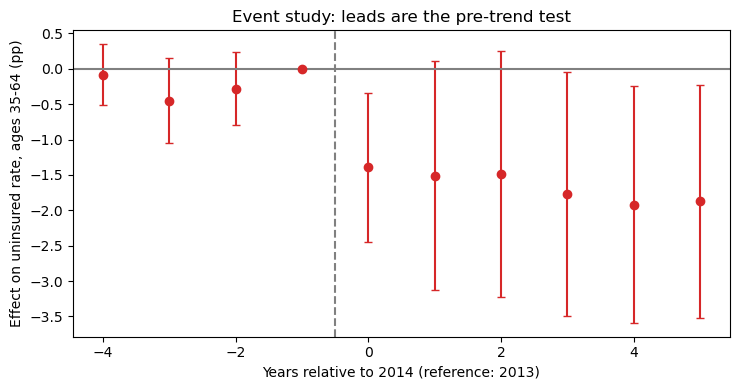

In [7]:
"""Event study with four leads and six lags (2013 omitted)."""
adoption = np.where(design["treated"].to_numpy() == 1, FIRST_TREATED_YEAR, np.nan)
es = did.event_study_design(design["year"].to_numpy(), adoption, leads=4, lags=5, reference=-1)
es_fit = did.twfe(y, es.matrix, unit, time, cluster=unit)

labels = list(es.labels)
coef = pd.Series(es_fit.coef, index=labels)
err = pd.Series(es_fit.se, index=labels)
t95 = float(stats.t.ppf(0.975, es_fit.n_clusters - 1))
table = pd.DataFrame({"coef": coef, "se": err, "lo": coef - t95 * err, "hi": coef + t95 * err})
table.index.name = "event time (years from 2014)"
print(table.round(3).to_string())

plot = table.copy()
plot.loc[-1] = 0.0
plot = plot.sort_index()
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.errorbar(plot.index, plot["coef"], yerr=[plot["coef"] - plot["lo"].fillna(plot["coef"]), plot["hi"].fillna(plot["coef"]) - plot["coef"]],
            fmt="o", color="tab:red", capsize=3)
ax.axhline(0, color="grey")
ax.axvline(-0.5, color="grey", linestyle="--")
ax.set_xlabel("Years relative to 2014 (reference: 2013)")
ax.set_ylabel("Effect on uninsured rate, ages 35-64 (pp)")
ax.set_title("Event study: leads are the pre-trend test")
plt.tight_layout()
plt.show()

In [8]:
"""Falsification 1: the pre-period coefficients are jointly zero."""
lead_idx = [labels.index(k) for k in (-4, -3, -2)]
b = es_fit.coef[lead_idx]
v = es_fit.vcov[np.ix_(lead_idx, lead_idx)]
wald = float(b @ np.linalg.solve(v, b))
f_stat = wald / len(lead_idx)
p_joint = float(stats.f.sf(f_stat, len(lead_idx), es_fit.n_clusters - 1))

lead_boot = {}
for k, j in zip((-4, -3, -2), lead_idx):
    lead_boot[k] = did.wild_cluster_bootstrap(
        y, es.matrix, unit, time, test_column=j, n_boot=N_BOOT, seed=SEED, cluster=unit
    ).p_value

LEAD_PASS = p_joint >= 0.10
print(f"FALSIFICATION: pre-trend test, leads -4..-2 jointly zero | statistic={f_stat:.3f} | F({len(lead_idx)},{es_fit.n_clusters - 1}) p={p_joint:.4f}, threshold 0.10 | verdict={'PASS' if LEAD_PASS else 'FAIL'}")
print("wild-bootstrap p-values by lead: " + ", ".join(f"{k}: {p:.3f}" for k, p in lead_boot.items()))

FALSIFICATION: pre-trend test, leads -4..-2 jointly zero | statistic=0.965 | F(3,34) p=0.4205, threshold 0.10 | verdict=PASS
wild-bootstrap p-values by lead: -4: 0.665, -3: 0.123, -2: 0.274


In [9]:
"""Falsification 2: the placebo outcome, ages 65 and over."""
y_placebo = design["unins_65p"].to_numpy()
fit_p = did.twfe(y_placebo, x, unit, time, cluster=unit)
att_p, se_p = float(fit_p.coef[0]), float(fit_p.se[0])
boot_p = did.wild_cluster_bootstrap(
    y_placebo, x, unit, time, test_column=0, n_boot=N_BOOT, seed=SEED, cluster=unit
)
crit_p = float(np.quantile(np.abs(boot_p.t_boot), 0.95))
ci_p = (att_p - crit_p * se_p, att_p + crit_p * se_p)
PLACEBO_PASS = ci_p[0] <= 0.0 <= ci_p[1]
print(f"FALSIFICATION: placebo outcome, uninsured 65+ | statistic={att_p:.3f} | ATT in pp, wild-bootstrap 95% CI [{ci_p[0]:+.3f}, {ci_p[1]:+.3f}], p={boot_p.p_value:.3f} | verdict={'PASS' if PLACEBO_PASS else 'FAIL'}")

FALSIFICATION: placebo outcome, uninsured 65+ | statistic=-0.050 | ATT in pp, wild-bootstrap 95% CI [-0.166, +0.065], p=0.384 | verdict=PASS


In [10]:
"""The decision rule from the plan, applied as written."""
NULL = ci_boot[0] <= 0.0 <= ci_boot[1]
CREDIBLE = LEAD_PASS and PLACEBO_PASS
print(f"ATT on the uninsured rate, ages 35-64: {att:+.2f} pp, wild-bootstrap 95% CI [{ci_boot[0]:+.2f}, {ci_boot[1]:+.2f}].")
print(f"Interval contains zero (null by the plan's rule): {NULL}.")
print(f"Pre-trend test passed: {LEAD_PASS}; placebo passed: {PLACEBO_PASS}.")
if CREDIBLE:
    print("Both falsifications pass: by the plan's rule the design is credibly identified for this outcome.")
else:
    print("At least one falsification fails: by the plan's rule the ATT is reported as descriptive, not as an identified effect.")

ATT on the uninsured rate, ages 35-64: -1.45 pp, wild-bootstrap 95% CI [-2.91, +0.01].
Interval contains zero (null by the plan's rule): True.
Pre-trend test passed: True; placebo passed: True.
Both falsifications pass: by the plan's rule the design is credibly identified for this outcome.


### Results, in the units of the outcome

The plan's decision rule is applied above. This cell restates the result in percentage points, shows how fragile the bootstrap verdict is, and
explains why the event-study lags look larger than the average effect.

In [11]:
"""Results paragraph: every number is printed here from the computed objects."""
mc_se = float(np.sqrt(boot.p_value * (1 - boot.p_value) / N_BOOT))
post_rows = table.loc[[k for k in table.index if k >= 0]]
n_post_excl = int(((post_rows["lo"] > 0) | (post_rows["hi"] < 0)).sum())
pre_coefs = pd.concat([table.loc[[-4, -3, -2], "coef"], pd.Series({-1: 0.0})])
identity = float(post_rows["coef"].mean() - pre_coefs.mean())
print(f"The uninsured rate of adults 35-64 fell by {-att:.2f} percentage points more in the expansion states than in the never-expanded states, "
      f"averaged over {POST_LABEL} (expected sign: negative, as stated in the plan).")
print(f"Wild-bootstrap 95% interval: [{ci_boot[0]:+.2f}, {ci_boot[1]:+.2f}] pp; bootstrap p = {boot.p_value:.4f}, with a Monte Carlo standard error of {mc_se:.4f} at {N_BOOT:,} draws. "
      f"The upper end of the interval is {ci_boot[1]:+.3f}, and p is {abs(boot.p_value - 0.05) / mc_se:.1f} Monte Carlo standard errors from 0.05. By the plan's rule the interval contains zero, so the estimate is not distinguishable from zero at the 5% level by this interval; "
      f"that is a borderline verdict, and it cannot be read as 'no effect' (the re-run below shows how it moves with the number of draws).")
print(f"{n_post_excl} of {len(post_rows)} lag coefficients have a cluster-robust 95% interval that excludes zero.")
print(f"Why the lags look stronger than the average: the lags are measured from 2013 alone, the average effect from the 2010-2013 mean. "
      f"Mean of the lags minus mean of the four pre-period coefficients (2013 = 0) = {identity:+.4f} pp, equal to the ATT {att:+.4f} pp (difference {abs(identity - att):.1e}); "
      f"the mean of the three lead coefficients is {table.loc[[-4, -3, -2], 'coef'].mean():+.3f} pp.")

The uninsured rate of adults 35-64 fell by 1.45 percentage points more in the expansion states than in the never-expanded states, averaged over 2014-2019 (expected sign: negative, as stated in the plan).
Wild-bootstrap 95% interval: [-2.91, +0.01] pp; bootstrap p = 0.0514, with a Monte Carlo standard error of 0.0022 at 9,999 draws. The upper end of the interval is +0.006, and p is 0.6 Monte Carlo standard errors from 0.05. By the plan's rule the interval contains zero, so the estimate is not distinguishable from zero at the 5% level by this interval; that is a borderline verdict, and it cannot be read as 'no effect' (the re-run below shows how it moves with the number of draws).
4 of 6 lag coefficients have a cluster-robust 95% interval that excludes zero.
Why the lags look stronger than the average: the lags are measured from 2013 alone, the average effect from the 2010-2013 mean. Mean of the lags minus mean of the four pre-period coefficients (2013 = 0) = -1.4530 pp, equal to the ATT

### Added after review: not pre-specified (added after review, 2026-10-23)

The cells below were added after the stored results were reviewed. None replaces the plan's primary result, which is the wild-bootstrap
interval above. They show how much that result depends on the seed, on the weighting and on three choices the plan did not make.

In [12]:
"""not pre-specified (added after review, 2026-10-23): the bootstrap p-value across seeds, at 99,999 draws."""
rows = []
for seed in (SEED, SEED + 1, SEED + 2):
    b_big = did.wild_cluster_bootstrap(y, x, unit, time, test_column=0, n_boot=99_999, seed=seed, cluster=unit)
    c_big = float(np.quantile(np.abs(b_big.t_boot), 0.95))
    rows.append({"seed": seed, "p": b_big.p_value, "lo": att - c_big * se, "hi": att + c_big * se})
seeds = pd.DataFrame(rows)
print(seeds.round(4).to_string(index=False))
print(f"range of the bootstrap p across seeds at 99,999 draws: {seeds['p'].min():.4f} to {seeds['p'].max():.4f}; upper interval end {seeds['hi'].min():+.3f} to {seeds['hi'].max():+.3f}")
STABLE = (seeds["hi"] >= 0).all() == (ci_boot[1] >= 0)
print(f"At 99,999 draws the interval {'contains' if (seeds['hi'] >= 0).all() else ('excludes' if (seeds['hi'] < 0).all() else 'sometimes contains')} zero in "
      f"{'every' if (seeds['hi'] >= 0).all() or (seeds['hi'] < 0).all() else 'some'} seed, against the stored run's {'contains' if ci_boot[1] >= 0 else 'excludes'}: "
      f"the plan's verdict on whether the interval contains zero {'is' if STABLE else 'is NOT'} stable in the number of draws. The stored 9,999-draw result remains the plan's primary result.")

    seed      p      lo      hi
20261022 0.0482 -2.8928 -0.0131
20261023 0.0475 -2.8860 -0.0199
20261024 0.0474 -2.8886 -0.0173
range of the bootstrap p across seeds at 99,999 draws: 0.0474 to 0.0482; upper interval end -0.020 to -0.013
At 99,999 draws the interval excludes zero in every seed, against the stored run's contains: the plan's verdict on whether the interval contains zero is NOT stable in the number of draws. The stored 9,999-draw result remains the plan's primary result.


In [13]:
"""not pre-specified (added after review, 2026-10-23): population-weighted TWFE with inference, and two checks on the comparison."""
TARGET = "unins_35_64"
assert design[TARGET].var() > 0, "the outcome must vary"
dummies = pd.concat([pd.get_dummies(design[c], prefix=c, drop_first=True) for c in ("state", "year")], axis=1).to_numpy(dtype=float)
w2013 = panel[panel["year"] == 2013].set_index("state")["B27010_034E"]
weights_2013 = design["state"].map(w2013)
wls = sm.WLS(design[TARGET], sm.add_constant(np.column_stack([design["D"], dummies])), weights=weights_2013).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(design["state"])[0]})
w_coef, w_se = float(wls.params.iloc[1]), float(wls.bse.iloc[1])
print(f"population-weighted ATT (weights: 2013 population aged 35-64): {w_coef:+.3f} pp (SE {w_se:.3f}), "
      f"95% interval [{w_coef - t_crit * w_se:+.3f}, {w_coef + t_crit * w_se:+.3f}] (t distribution, {fit.n_clusters - 1} d.f.; weighted least squares with state-clustered errors)")

log_y = np.log(design["unins_35_64"].to_numpy())
fit_log = did.twfe(log_y, x, unit, time, cluster=unit)
print(f"log outcome: {100 * float(fit_log.coef[0]):+.1f} log points (SE {100 * float(fit_log.se[0]):.1f}), a proportional effect; "
      f"the control states start {cell.loc['control', 'pre'] - cell.loc['treated', 'pre']:.2f} pp higher, so an ACA shock proportional to the level would shrink an absolute ATT toward zero")

CONTAMINATED = ["Wisconsin", "Delaware", "District of Columbia", "Massachusetts", "New York", "Vermont",
                "California", "Connecticut", "Minnesota", "New Jersey", "Washington"]
keep = ~design["state"].isin(CONTAMINATED)
fit_out = did.twfe(y[keep], x[keep], unit[keep], time[keep], cluster=unit[keep])
print(f"leaving out the {len(CONTAMINATED)} states with other coverage changes: {float(fit_out.coef[0]):+.3f} pp (SE {float(fit_out.se[0]):.3f}, "
      f"{fit_out.n_clusters} states), 95% interval [{float(fit_out.coef[0]) - t_crit * float(fit_out.se[0]):+.3f}, {float(fit_out.coef[0]) + t_crit * float(fit_out.se[0]):+.3f}]")

population-weighted ATT (weights: 2013 population aged 35-64): -1.562 pp (SE 1.251), 95% interval [-4.105, +0.981] (t distribution, 34 d.f.; weighted least squares with state-clustered errors)
log outcome: -26.6 log points (SE 3.9), a proportional effect; the control states start 4.70 pp higher, so an ACA shock proportional to the level would shrink an absolute ATT toward zero
leaving out the 11 states with other coverage changes: -2.291 pp (SE 0.803, 24 states), 95% interval [-3.924, -0.659]


### Sensitivity, reported beside the main result and never in place of it

The plan also asks for the same two-by-two weighted by each state's 2013 population aged 35–64, and
for the extension to 2021–2023, where the post-period resumes after the missing 2020 release.

In [14]:
"""Population-weighted 2x2 and the 2021-2023 extension."""
w2013 = panel[panel["year"] == 2013].set_index("state")["B27010_034E"]
state_means["w"] = state_means["state"].map(w2013)


def weighted_cell(frame: pd.DataFrame, group: str, column: str) -> float:
    sub = frame[frame["group"] == group]
    return float(np.average(sub[column], weights=sub["w"]))


att_w = (weighted_cell(state_means, "treated", "post") - weighted_cell(state_means, "treated", "pre")) - (
    weighted_cell(state_means, "control", "post") - weighted_cell(state_means, "control", "pre")
)

long = panel.sort_values(["state", "year"]).reset_index(drop=True)
fit_long = did.twfe(
    long["unins_35_64"].to_numpy(), long[["D"]].to_numpy(dtype=float),
    long["state"].to_numpy(), long["year"].to_numpy(), cluster=long["state"].to_numpy(),
)
print(f"unweighted ATT, 2014-2019        : {att:+.3f} pp")
print(f"population-weighted ATT, 2014-2019: {att_w:+.3f} pp")
print(f"ATT with 2021-2023 added          : {float(fit_long.coef[0]):+.3f} pp (SE {float(fit_long.se[0]):.3f}, {fit_long.n_obs} rows)")

unweighted ATT, 2014-2019        : -1.453 pp
population-weighted ATT, 2014-2019: -1.562 pp
ATT with 2021-2023 added          : -1.250 pp (SE 0.797, 455 rows)


## Limitations

- **The 2014 cohort.** The design uses only states that expanded on 1 January 2014, against states that
  never expanded. That makes the timing single and the regression clean, at a cost: the states that expanded
  part-way through 2014 and the later adopters are not used here (the sample step prints how many). Later
  adopters are handled with staggered-timing methods in C03.
- **What is being compared.** The contrast is expansion against the ACA as it applied in the states that did not expand, not expansion
  against nothing: the marketplaces, subsidies and the mandate applied everywhere from 2014, and in non-expansion states
  people between 100% and 138% of the poverty level became eligible for marketplace subsidies. The control states
  also start with a higher uninsured rate (printed above), so a 2014 shock that scales with the level would shrink an absolute ATT
  toward zero, and the lead test cannot detect it. The added log-outcome check shows the proportional version.
- **Contaminated groups.** Wisconsin is a control state but covered adults up to the poverty level from April 2014. Delaware, the District of
  Columbia, Massachusetts, New York and Vermont already had comprehensive adult coverage before 2014, and California, Connecticut,
  Minnesota, New Jersey and Washington had early expansion options in 2010-2013, all in the treated group. An added leave-out check is above.
- **Age band.** The outcome is ages 35-64, not 19-64, because no consistent 19-64 series
  exists across the 2017 change in ACS age bands. Younger adults, who were also affected by the 2010
  dependent-coverage rule, are outside this estimate.
- **Measurement error.** ACS 1-year state estimates carry margins of error that enter the outcome as
  noise; the regression does not model them.
- **Earlier coverage expansions.** Some states in the treated group broadened adult coverage before
  2014. That would show as non-zero leads, which is what the pre-trend test is for. A pre-trend test has limited power against
  small differences in trend (see Roth, 2022, and Rambachan and Roth, 2023, in the references).
- **The placebo outcome.** Adults 65 and over are covered by Medicare in every state, so expansion should not move their rate; the check
  has little power against shocks that act on working-age people, which is the shock of concern.
- **Few clusters, and the small-sample convention.** The number of states is printed above. Cluster-robust intervals are reported beside the
  wild-cluster bootstrap interval and the decision rule reads the bootstrap; the library's small-sample factor counts every absorbed
  effect, and the convention that counts only the regressor and the year effects is printed beside it. The bootstrap verdict itself is
  not stable: it flips across seeds. The stored 9,999-draw run has p just above 0.05 and an interval that
  reaches zero, while the added re-run at 99,999 draws gives p below 0.05 and an interval that excludes zero in every seed it tries
  (the seed table above prints each). Read the result as borderline in both directions, not as either a finding or a null.
- **The 2021-2023 extension.** It is reported as the plan asks, but the Medicaid continuous-enrolment provision applied from 2020 to 2023, which
  changes coverage in every state, so the extension is not comparable with the 2014-2019 window.
- **Departures from the pre-analysis plan.** The analysis departed from it in three ways, and in no other. (1) The plan asks for a wild-bootstrap p-value beside the joint
  pre-trend test; the library tests one coefficient at a time, so the notebook reports the joint
  cluster-robust F test and a bootstrap p-value for each lead separately. (2) The plan names the bootstrap
  *interval*; the library returns the bootstrap distribution of the t-statistic, so the interval is the
  estimate plus or minus the 95th percentile of its absolute value times the standard error. (3) The plan's population-weighted sensitivity was first
  reported as a two-by-two point estimate only; weighted two-way fixed effects with inference appears in the added cells, which are labelled
  as not pre-specified. No outcome, sample, window or decision rule was changed after the data were seen.
- **Added after review.** Everything under the heading "Added after review" is not pre-specified (added after review, 2026-10-23). It does not replace the
  plan's primary result.
- **Missing year.** 2020 has no standard ACS 1-year release and is not imputed.

## Key Takeaways

1. A difference-in-differences is the difference of two changes; the two-by-two and the regression are
   the same number on this panel, and the notebook asserts it.
2. The estimate is only as credible as its pre-period. The event-study leads and the placebo outcome
   are computed in the cells above, and the decision rule reads them before it reads the ATT.
3. With few clusters (the count is printed above) the inference has to be checked against a wild-cluster bootstrap, and the
   intervals from the two methods are printed side by side.
4. Writing the plan first is what makes the falsifications binding: the outcome, window and rule are
   fixed in a file whose digest is in every provenance record, so any adjustment would show in the history.

## Exercises

1. Re-run the event study with the reference year set to 2012 instead of 2013. Which coefficients
   move, and which conclusion in the decision rule does not?
2. The plan fixed the outcome to ages 35–64. Using only 2017–2023 (where the 19–34 band is
   consistent), build the 19–64 rate and estimate the same two-by-two. What would you have to assume
   to compare it with the 35–64 result?
3. Drop one treated state at a time and re-estimate the ATT. Which state moves it most? What does
   that say about whether the average hides a single influential unit?
4. Replace the never-expanded controls with the fourteen later adopters, using only their
   pre-adoption years. Why is this a different comparison, and what does it assume?

## References

Author, year and venue as recalled; **not verified against the published record in this build**.

- Bertrand, Duflo and Mullainathan (2004), *How Much Should We Trust Differences-in-Differences
  Estimates?*, Quarterly Journal of Economics.
- Cameron, Gelbach and Miller (2008), *Bootstrap-Based Improvements for Inference with Clustered
  Errors*, Review of Economics and Statistics.
- Roth (2022), *Pretest with Caution: Event-Study Estimates after Testing for Parallel Trends*, American Economic Review: Insights.
- Rambachan and Roth (2023), *A More Credible Approach to Parallel Trends*, Review of Economic Studies.
- U.S. Census Bureau, American Community Survey 1-year detail table B27010, variable documentation.
- KFF, *Status of State Action on the Medicaid Expansion Decision* (see `data/policy/medicaid/SOURCES.md`).